In [8]:
import numpy as np
import pandas as pd

In [9]:
from pathlib import Path

data_path = Path("/run/media/ddd0604/New Volume/code/ML/project1/placement.csv")
df = pd.read_csv(data_path)

print(df.head(), "\n")
print(df.shape)

   Unnamed: 0  cgpa     iq  placement
0           0   6.8  123.0          1
1           1   5.9  106.0          0
2           2   5.3  121.0          0
3           3   7.4  132.0          1
4           4   5.8  142.0          0 

(100, 4)


In [10]:
#Steps:

##0. Preprocessing + EDA + Feature selection
##1. Extract input and output columns
##2. Scale the values of the input columns
##3. Train test split
##4. Train the model
##5. Evaluate the model/model selection
##6. Deploy the model

In [11]:
df.info() #to check the null values and data types of the columns

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [12]:
df = df.iloc[:, 1:] #removing the first column as it is not useful for prediction

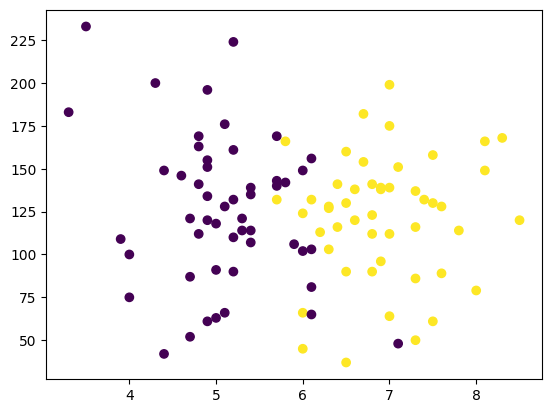

In [13]:
import matplotlib.pyplot as plt
plt.scatter(df['cgpa'], df['iq'], c = df['placement'])

In [14]:
#step: extract the input and output columns

X = df.iloc[: , 0:2] # the input features
y = df.iloc[: , -1]  
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = .1)

In [16]:
X_train

,cgpa,iq
7,5.0,63.0
5,7.1,48.0
9,5.1,66.0
94,4.7,52.0
45,6.0,66.0
...,...,...
12,5.4,139.0
11,6.9,138.0
29,7.0,112.0
88,4.4,149.0


In [17]:
y_train

7     0
5     0
9     0
94    0
45    1
     ..
12    0
11    1
29    1
88    0
15    0
Name: placement, Length: 90, dtype: int64

In [18]:
#Scale the values
from sklearn.preprocessing import StandardScaler

In [19]:
scaler = StandardScaler()  #standard scaler to make the values in between -1 to 1

In [20]:
X_train = scaler.fit_transform(X_train)
X_train

array([[-0.93124946, -1.55724126],
       [ 0.90597547, -1.93602968],
       [-0.84376256, -1.48148358],
       [-1.19371017, -1.83501944],
       [-0.05638045, -1.48148358],
       [ 0.03110645, -1.50673614],
       [ 1.25592308,  0.13468033],
       [-0.75627566,  0.18518545],
       [ 1.78084449,  0.61447899],
       [ 1.34340998, -0.90067468],
       [ 0.81848857, -1.5319887 ],
       [ 1.08094927, -0.97643236],
       [ 0.29356716, -0.21885553],
       [-0.66878876, -0.09259272],
       [ 0.38105406, -0.87542212],
       [ 0.90597547,  0.66498411],
       [ 0.64351476,  0.4124585 ],
       [ 0.73100167,  0.36195337],
       [-1.01873636,  0.66498411],
       [ 0.64351476, -0.0420876 ],
       [-0.05638045,  0.61447899],
       [-0.05638045, -0.57239138],
       [ 0.64351476, -0.31986577],
       [ 0.38105406, -2.21380785],
       [-1.01873636, -1.60774639],
       [ 0.46854096, -0.11784528],
       [-2.41852679,  1.47306606],
       [ 1.08094927, -0.21885553],
       [ 1.78084449,

In [21]:
X_test = scaler.transform(X_test)
X_test

array([[-0.05638045, -2.01178736],
       [-1.01873636,  0.23569057],
       [-1.80611848, -0.62289651],
       [ 0.38105406,  0.13468033],
       [-0.31884115,  0.18518545],
       [-0.93124946, -0.16835041],
       [-1.45617087, -2.08754505],
       [-1.10622327,  1.11953021],
       [ 0.55602786,  0.74074179],
       [-0.66878876, -0.26936065]])

In [22]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()

In [23]:
#model training
clf.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [24]:
#step : Evaluate the model

y_pred = clf.predict(X_test)

In [25]:
y_test

10    1
40    0
18    0
57    1
87    1
67    0
96    0
75    0
74    1
46    0
Name: placement, dtype: int64

In [26]:
from sklearn.metrics import accuracy_score
x = accuracy_score(y_test, y_pred)
print(x)

0.8


<Axes: >

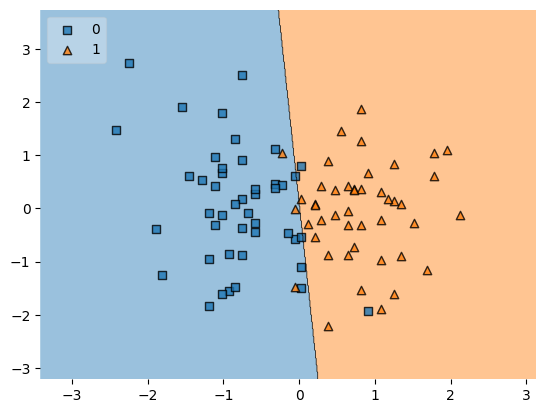

In [27]:
# to visualize the pattern which has been learned by the ML model

from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

In [28]:
import pickle

In [31]:
from pathlib import Path
import pickle

#pickle convert a object into a file for further use in deploying
model_path = data_path.parent / "model.pkl"  # save next to the dataset
with open(model_path, "wb") as file:
    pickle.dump(clf, file)

print(f"Model saved to: {model_path}")

Model saved to: /run/media/ddd0604/New Volume/code/ML/project1/model.pkl
